# Bank Marketing: Predicting Term-Deposit Subscription

**Business question:** Which clients are most likely to subscribe to a term deposit, and how should the bank prioritise its marketing calls?

**Dataset:** UCI *Bank Marketing* (`bank-additional-full.csv`) – 41,188 phone-call records from a Portuguese bank's direct-marketing campaigns (Finance / Marketing).

**Target variable:** `y` → `target` (1 = subscribed, 0 = did not subscribe).

| Project requirement | Where it is covered |
|---|---|
| Dataset with numeric + categorical variables, missing values and outliers | §1 (missing values are encoded as `unknown`; heavy outliers in `duration`, `campaign`, `age`) |
| Data cleaning & preparation (AI-assisted) | §2 – missing values, duplicates, data types, outliers (IQR + Z-score), Isolation-Forest anomaly detection, AI cleaning advisor, feature engineering |
| EDA & visualisation | §3 – histograms, bar charts, line charts, scatter plots, correlation heat-map, key insights |
| Predictive modelling | §4 – Logistic Regression, Decision Tree, Random Forest, Linear Regression, SVM; accuracy + confusion matrix (+ recall / F1 / ROC-AUC) |
| AI-generated insights & summary | §5 – automatic natural-language insights, explanation of model results, business recommendations, Generative-AI prompt |
| Interactive dashboard (Power BI / Tableau) | §6 – dashboard-ready exports + build guide (KPIs, slicers, drill-down, predictive page) |
| Face-cam walkthrough | §7 – recording script and deliverables checklist |

In [33]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             r2_score, mean_squared_error)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

## 1) Load & Inspect the Data

**Why this dataset fits the brief**
- Structured, tabular, **Finance / Marketing** data (20 predictors, ~41k rows).
- **Numerical** (`age`, `duration`, `campaign`, `euribor3m` …) and **categorical** variables (`job`, `education`, `month` …).
- **Missing values** – stored as the text `unknown` (e.g. `default`, `education`, `housing`).
- **Outliers** – very long calls (`duration`), many repeated calls (`campaign`), older clients (`age`).
- A clear **binary target** – did the client subscribe (`y`)?

In [65]:
df = pd.read_csv('bank-additional-full.csv', sep=';')
print('Shape:', df.shape)


Shape: (41188, 21)


In [66]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [68]:
display(df.describe().T.round(2))
print('\nTarget distribution (raw):')
print(df['y'].value_counts(normalize=True).round(3))

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10



Target distribution (raw):
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


## 2) Data Cleaning & Preparation (AI-Assisted)

**Leakage-safe workflow.** Every statistic that is *learned from data* (mode used for imputation, IQR capping bounds, Isolation-Forest model, Euribor tertile cut-offs, scaler, encoder) is **fitted on the training set only** and then applied unchanged to the test set. The train/test split is therefore made **before** any of these steps (§2.4).

### 2.1 Missing values
In this dataset missing values are stored as the string `'unknown'`, so pandas does not see them as missing. We convert them to real `NaN` first (this step only *identifies* them – nothing is learned from the data yet).

,missing_count,missing_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


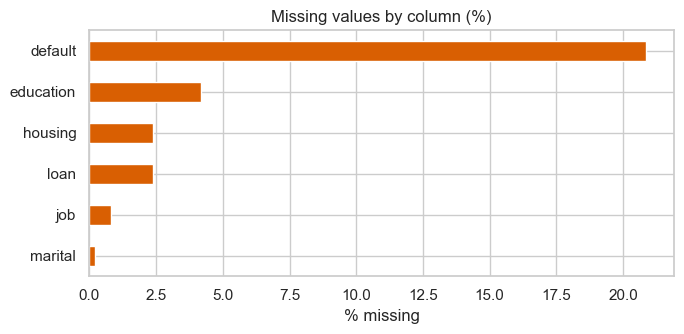

In [36]:
df = df.replace('unknown', np.nan)

missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2)
})
missing = missing[missing['missing_count'] > 0].sort_values('missing_pct', ascending=False)
display(missing)

ax = missing['missing_pct'].plot(kind='barh', color=ORANGE, figsize=(7, 3.5))
ax.set_title('Missing values by column (%)')
ax.set_xlabel('% missing')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 2.2 Duplicate rows
Removing exact duplicates is safe before splitting (it prevents the same record from landing in both train and test).

In [37]:
n_dup = int(df.duplicated().sum())
print(f'Duplicated rows found: {n_dup}')
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Duplicated rows found: 12
Shape after removing duplicates: (41176, 21)


### 2.3 Column formatting
Column names with dots (`emp.var.rate`) are renamed 


In [38]:
df.columns = df.columns.str.replace('.', '_', regex=False)
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
day_order = ['mon', 'tue', 'wed', 'thu', 'fri']
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']


### 2.4 Train / test split 

A stratified 80/20 split is created now. From this point on, all learned statistics come from `train_mask` rows only.

In [39]:
df['target'] = df['y'].map({'yes': 1, 'no': 0}).astype(int)

train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=df['target'])
df['dataset_split'] = np.where(df.index.isin(train_idx), 'Train', 'Test')
train_mask = (df['dataset_split'] == 'Train')

print(df['dataset_split'].value_counts().to_string())
print('Subscription rate – train: {:.3f} | test: {:.3f}'.format(
    df.loc[train_mask, 'target'].mean(), df.loc[~train_mask, 'target'].mean()))

dataset_split
Train    32940
Test      8236
Subscription rate – train: 0.113 | test: 0.113


### 2.5 Imputing missing values
- **`default`** (~21% missing): the *unknown* group behaves differently from both *yes* and *no*, so "unknown" is itself informative → keep it as its own category.
- **`job`, `marital`, `education`, `housing`, `loan`** (< 5% missing each): impute with the **mode of the training rows**, applied to train and test alike.

In [40]:
# Evidence for keeping 'unknown' as its own category in `default`
default_rate = df_raw.groupby('default')['y'].apply(lambda s: round((s == 'yes').mean() * 100, 1))
print('Subscription rate (%) by `default` status in the raw data:')
print(default_rate.to_string())

df['default'] = df['default'].fillna('unknown')

impute_values = {c: df.loc[train_mask, c].mode()[0] for c in ['job', 'marital', 'education', 'housing', 'loan']}
for c, v in impute_values.items():
    df[c] = df[c].fillna(v)

print('\nModes learned from the TRAIN set:', impute_values)
print('Remaining missing values:', int(df.isna().sum().sum()))

Subscription rate (%) by `default` status in the raw data:
default
no         12.9
unknown     5.2
yes         0.0

Modes learned from the TRAIN set: {'job': 'admin.', 'marital': 'married', 'education': 'university.degree', 'housing': 'yes', 'loan': 'no'}
Remaining missing values: 0


### 2.6 Data types
Text columns → `category`; `month` and `day_of_week` become **ordered** categories so charts sort chronologically. 

In [41]:
cat_cols = [c for c in df.select_dtypes(include='object').columns if c not in ('y',)]
for c in cat_cols:
    df[c] = df[c].astype('category')
df['month'] = pd.Categorical(df['month'].astype(str), categories=month_order, ordered=True)
df['day_of_week'] = pd.Categorical(df['day_of_week'].astype(str), categories=day_order, ordered=True)

print('Categorical columns:', cat_cols)
display(df.dtypes.to_frame('dtype').T)

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'dataset_split']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,target,dataset_split
dtype,int64,category,category,category,category,category,category,category,category,category,int64,int64,int64,int64,category,float64,float64,float64,float64,float64,object,int64,category


### 2.7 Outlier detection & treatment (statistical methods, bounds from the training set)
Two standard methods are compared:
- **IQR rule**: outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`
- **Z-score rule**: `|z| > 3`

**Treatment:** *winsorising* (capping) at the IQR bounds **computed on the training rows**, then applied to all rows. `age` and `campaign` are predictors. `duration` is capped only to make the *EDA* charts readable – it is **never used as a predictor** (see §4).
`previous` and `pdays` are zero-inflated (most clients were never contacted before), so an IQR cap would wrongly flatten real information – they are left untouched.

In [42]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

train_df = df[train_mask]
num_check = ['age', 'duration', 'campaign', 'previous', 'cons_conf_idx']
rows = []
for c in num_check:
    lo, hi = iqr_bounds(train_df[c])
    z = (train_df[c] - train_df[c].mean()) / train_df[c].std()
    n_iqr = int(((train_df[c] < lo) | (train_df[c] > hi)).sum())
    rows.append({'column': c, 'skewness': round(train_df[c].skew(), 2),
                 'IQR_lower': round(lo, 1), 'IQR_upper': round(hi, 1),
                 'outliers_IQR': n_iqr, 'outliers_IQR_pct': round(n_iqr / len(train_df) * 100, 2),
                 'outliers_Zscore': int((z.abs() > 3).sum())})
outlier_report = pd.DataFrame(rows).set_index('column')
display(outlier_report)

,skewness,IQR_lower,IQR_upper,outliers_IQR,outliers_IQR_pct,outliers_Zscore
column,,,,,,
age,0.80,9.5,69.5,383,1.16,303
duration,3.19,-223.5,644.5,2349,7.13,686
campaign,4.89,-2.0,6.0,1911,5.80,676
previous,3.89,0.0,0.0,4509,13.69,849
cons_conf_idx,0.31,-52.2,-26.9,357,1.08,0


Capping bounds (from train): {'age': (np.float64(9.5), np.float64(69.5)), 'duration': (0, np.float64(644.5)), 'campaign': (0, np.float64(6.0))}


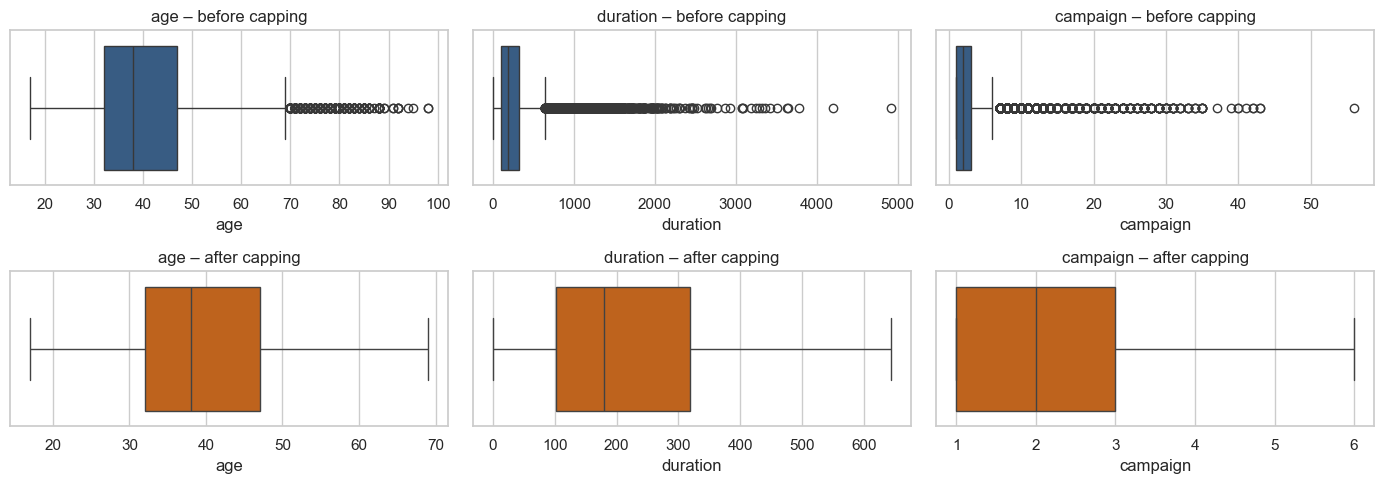

In [43]:
cap_cols = ['age', 'duration', 'campaign']
df_before = df[cap_cols].copy()

cap_bounds = {c: (max(0, iqr_bounds(train_df[c])[0]), iqr_bounds(train_df[c])[1]) for c in cap_cols}  # TRAIN only, lower bound never below 0
for c, (lo, hi) in cap_bounds.items():
    df[c] = df[c].clip(lo, hi).astype(int)                          # applied to ALL rows
print('Capping bounds (from train):', {k: (round(v[0], 1), round(v[1], 1)) for k, v in cap_bounds.items()})

fig, axes = plt.subplots(2, 3, figsize=(14, 5))
for j, c in enumerate(cap_cols):
    sns.boxplot(x=df_before[c], ax=axes[0, j], color=BLUE)
    axes[0, j].set_title(f'{c} – before capping')
    sns.boxplot(x=df[c], ax=axes[1, j], color=ORANGE)
    axes[1, j].set_title(f'{c} – after capping')
plt.tight_layout()
plt.show()

### 2.8 AI-assisted anomaly detection (Isolation Forest) – used as a *signal*, not a filter
Univariate rules look at one column at a time. An **Isolation Forest** (unsupervised, fitted on the **training rows only**) finds records that are unusual **across several variables together**.

These records are **not deleted**. As the numbers below show, they convert far better than normal records – they are a valuable marketing segment (unusual economic periods), not data errors. The flag `is_anomaly` is therefore kept as a **feature and a dashboard filter**. It is built only from predictors (never from the target), so it does not leak the outcome.

In [44]:
iso_cols = ['age', 'campaign', 'previous', 'emp_var_rate', 'cons_price_idx',
            'cons_conf_idx', 'euribor3m', 'nr_employed']

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=RANDOM_STATE)
iso.fit(df.loc[train_mask, iso_cols])                                # fit on TRAIN only
df['is_anomaly'] = (iso.predict(df[iso_cols]) == -1).astype(int)     # apply to all rows

n_anom = int(df['is_anomaly'].sum())
print(f'Anomalous records flagged: {n_anom} ({n_anom / len(df):.2%})')
print('Subscription rate (training rows) – anomalies: {:.1f}% | normal records: {:.1f}%'.format(
    df.loc[train_mask & (df.is_anomaly == 1), 'target'].mean() * 100, df.loc[train_mask & (df.is_anomaly == 0), 'target'].mean() * 100))
anom_months = df.loc[train_mask & (df.is_anomaly == 1), 'month'].astype(str).value_counts(normalize=True).mul(100).round(1)
print('Share of anomalies by month (%):', anom_months.head(5).to_dict())
display(df.groupby('is_anomaly')[iso_cols].mean().round(2))

Anomalous records flagged: 404 (0.98%)
Subscription rate (training rows) – anomalies: 45.5% | normal records: 10.9%
Share of anomalies by month (%): {'oct': 31.5, 'nov': 28.8, 'sep': 14.5, 'aug': 7.9, 'jul': 4.2}


,age,campaign,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
is_anomaly,,,,,,,,
0,39.87,2.27,0.15,0.10,93.57,-40.49,3.65,5168.82
1,46.50,2.72,2.30,-1.79,93.91,-41.31,0.89,4987.03


### 2.9 AI cleaning advisor
A rule-based assistant that reads the data profile and writes cleaning recommendations in plain English. (The same findings can be pasted into a Generative-AI tool for a second opinion – see the prompt in §5.)

In [45]:
def ai_cleaning_advisor():
    recs = []
    recs.append(f'Duplicates: {n_dup} exact duplicate rows were found and removed so no record is double-counted or split across train and test.')
    recs.append('Leakage control: the train/test split is made first; imputation modes, capping bounds, the anomaly model, tertile cut-offs, scaler and encoder are all fitted on training rows only.')
    for col, r in missing.iterrows():
        if r['missing_pct'] >= 10:
            recs.append(f"Missing data: '{col}' has {r['missing_pct']:.1f}% missing – too much to impute safely, "
                        f"so it was kept as an explicit 'unknown' category (it carries signal).")
        else:
            recs.append(f"Missing data: '{col}' has only {r['missing_pct']:.1f}% missing – imputed with the training-set mode ('{impute_values[col]}').")
    for col, r in outlier_report.iterrows():
        if r['outliers_IQR_pct'] >= 5 and col in cap_cols:
            note = ' (EDA only – not a predictor)' if col == 'duration' else ''
            recs.append(f"Outliers: '{col}' is heavily skewed (skew = {r['skewness']}) with {r['outliers_IQR_pct']:.1f}% of training values "
                        f"outside the IQR fences – capped at [{max(r['IQR_lower'],0):.0f}, {r['IQR_upper']:.0f}]{note}.")
        elif col == 'previous':
            recs.append(f"Outliers: '{col}' is zero-inflated – left unchanged because capping would erase real information.")
    share_999 = (df_raw['pdays'] == 999).mean() * 100
    recs.append(f"Sentinel value: pdays = 999 means 'never contacted' for {share_999:.1f}% of rows. It is NOT converted to 0 days "
                f"(that would wrongly mean 'contacted today'); instead it becomes the category 'Never contacted' in pdays_bucket plus a previously_contacted flag.")
    a_rate = df.loc[train_mask & (df.is_anomaly == 1), 'target'].mean() * 100
    recs.append(f"Anomalies: {n_anom} multivariate anomalies were flagged. They convert at {a_rate:.0f}% – a strong business segment, so they are kept and used as a feature, not removed.")
    recs.append("Leakage warning: 'duration' (call length) is only known after the call ends, so it is used for analysis "
                "but explicitly removed from the prediction models (an assertion in §4 enforces this).")
    return recs

for i, r in enumerate(ai_cleaning_advisor(), 1):
    print(f'{i}. {r}')

1. Duplicates: 12 exact duplicate rows were found and removed so no record is double-counted or split across train and test.
2. Leakage control: the train/test split is made first; imputation modes, capping bounds, the anomaly model, tertile cut-offs, scaler and encoder are all fitted on training rows only.
3. Missing data: 'default' has 20.9% missing – too much to impute safely, so it was kept as an explicit 'unknown' category (it carries signal).
4. Missing data: 'education' has only 4.2% missing – imputed with the training-set mode ('university.degree').
5. Missing data: 'housing' has only 2.4% missing – imputed with the training-set mode ('yes').
6. Missing data: 'loan' has only 2.4% missing – imputed with the training-set mode ('no').
7. Missing data: 'job' has only 0.8% missing – imputed with the training-set mode ('admin.').
8. Missing data: 'marital' has only 0.2% missing – imputed with the training-set mode ('married').
9. Outliers: 'duration' is heavily skewed (skew = 3.19) w

### 2.10 Feature engineering
New features that make the analysis (and the dashboard) more meaningful:

| Feature | Description |
|---|---|
| `target_label` | Readable label for the binary target |
| `previously_contacted` | 1 if the client was contacted in a previous campaign |
| `pdays_bucket` | Never contacted / Within 6 days / 7-14 days / 15+ days since the previous contact (replaces the 999 sentinel) |
| `age_group` | 18-30 / 31-45 / 46-60 / 60+ |
| `campaign_group` | 1 call / 2-3 / 4-5 / 6+ calls in this campaign (`campaign` is capped at 6) |
| `euribor_level` | Low / Medium / High 3-month Euribor (tertile cut-offs from the **training** rows) |
| `job_type` | Job grouped into 5 business segments |
| `month_num` | Month as a number (for sorting / time axis) |
| `duration_group` | Call-length bands – **post-call information: EDA / dashboard only, never a model input** |

In [46]:
df['target_label'] = df['target'].map({1: 'Subscribed', 0: 'No Subscription'})
df['previously_contacted'] = (df['pdays'] != 999).astype(int)
df['pdays_bucket'] = np.select([df['pdays'] == 999, df['pdays'] <= 6, df['pdays'] <= 14],
                               ['Never contacted', 'Within 6 days', '7-14 days'], default='15+ days')
df['pdays_bucket'] = pd.Categorical(df['pdays_bucket'],
                                    categories=['Never contacted', 'Within 6 days', '7-14 days', '15+ days'], ordered=True)

df['age_group'] = pd.cut(df['age'], bins=[0, 30, 45, 60, 100], labels=['18-30', '31-45', '46-60', '60+'])
df['campaign_group'] = pd.cut(df['campaign'], bins=[0, 1, 3, 5, 100],
                              labels=['1 call', '2-3 calls', '4-5 calls', '6+ calls'])

q1, q2 = df.loc[train_mask, 'euribor3m'].quantile([1 / 3, 2 / 3])    # cut-offs from TRAIN only
df['euribor_level'] = pd.cut(df['euribor3m'], bins=[-np.inf, q1, q2, np.inf], labels=['Low', 'Medium', 'High'])

job_map = {'admin.': 'White-collar', 'management': 'White-collar', 'technician': 'White-collar',
           'entrepreneur': 'White-collar', 'self-employed': 'White-collar',
           'blue-collar': 'Blue-collar / Service', 'services': 'Blue-collar / Service',
           'housemaid': 'Blue-collar / Service',
           'student': 'Student / Retired', 'retired': 'Student / Retired',
           'unemployed': 'Unemployed'}
df['job_type'] = df['job'].astype(str).map(job_map).astype('category')

df['month_num'] = df['month'].map({m: i + 3 for i, m in enumerate(month_order)}).astype(int)
df['duration_group'] = pd.cut(df['duration'], bins=[-1, 60, 180, 360, 10000],
                              labels=['<1 min', '1-3 min', '3-6 min', '6+ min'])

# Export the cleaned dataset (deliverable #1). It keeps post-call columns for analysis; models never see them.
df.to_csv(f'{OUTPUT_DIR}/bank_cleaned_master.csv', index=False)
print('Cleaned dataset saved ->', f'{OUTPUT_DIR}/bank_cleaned_master.csv', '| shape:', df.shape)
df.head()

Cleaned dataset saved -> outputs/bank_cleaned_master.csv | shape: (41176, 33)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,target,dataset_split,is_anomaly,target_label,previously_contacted,pdays_bucket,age_group,campaign_group,euribor_level,job_type,month_num,duration_group
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,Train,0,No Subscription,0,Never contacted,46-60,1 call,Medium,Blue-collar / Service,5,3-6 min
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,Test,0,No Subscription,0,Never contacted,46-60,1 call,Medium,Blue-collar / Service,5,1-3 min
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,Train,0,No Subscription,0,Never contacted,31-45,1 call,Medium,Blue-collar / Service,5,3-6 min
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,Train,0,No Subscription,0,Never contacted,31-45,1 call,Medium,White-collar,5,1-3 min
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,Train,0,No Subscription,0,Never contacted,46-60,1 call,Medium,Blue-collar / Service,5,3-6 min


## 3) Exploratory Data Analysis & Visualisation
All EDA statistics and charts use the **training rows only** (`eda`), so conclusions are not influenced by the test set.

Overall subscription rate: 11.27%  (3,711 of 32,940 contacts)


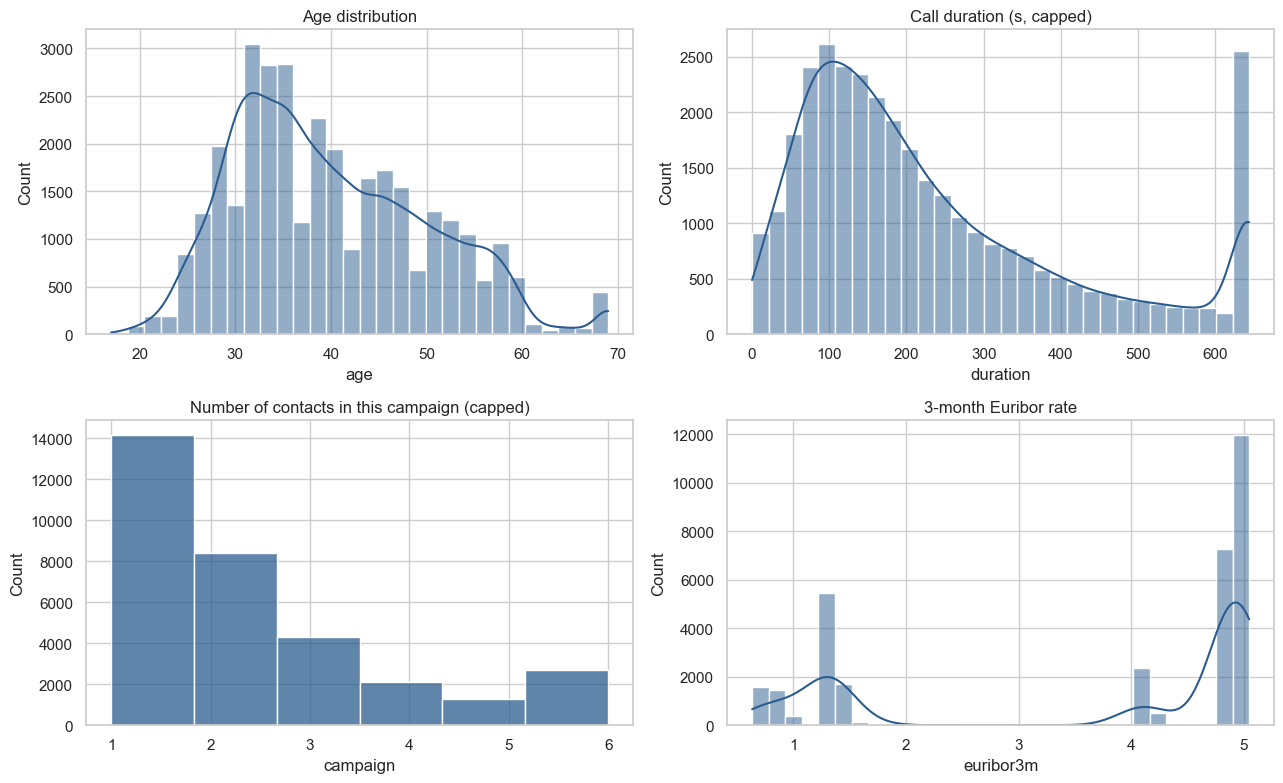

In [47]:
eda = df[train_mask]          # EDA on TRAINING rows only
overall_rate = eda['target'].mean() * 100
print(f'Overall subscription rate: {overall_rate:.2f}%  ({eda.target.sum():,} of {len(eda):,} contacts)')

def rate_by(col):
    return eda.groupby(col, observed=True)['target'].mean() * 100

# 3.1 Distributions – histograms
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(eda['age'], bins=30, kde=True, ax=ax[0, 0], color=BLUE);        ax[0, 0].set_title('Age distribution')
sns.histplot(eda['duration'], bins=30, kde=True, ax=ax[0, 1], color=BLUE);   ax[0, 1].set_title('Call duration (s, capped)')
sns.histplot(eda['campaign'], bins=6, ax=ax[1, 0], color=BLUE);              ax[1, 0].set_title('Number of contacts in this campaign (capped)')
sns.histplot(eda['euribor3m'], bins=30, kde=True, ax=ax[1, 1], color=BLUE);  ax[1, 1].set_title('3-month Euribor rate')
plt.tight_layout()
plt.show()

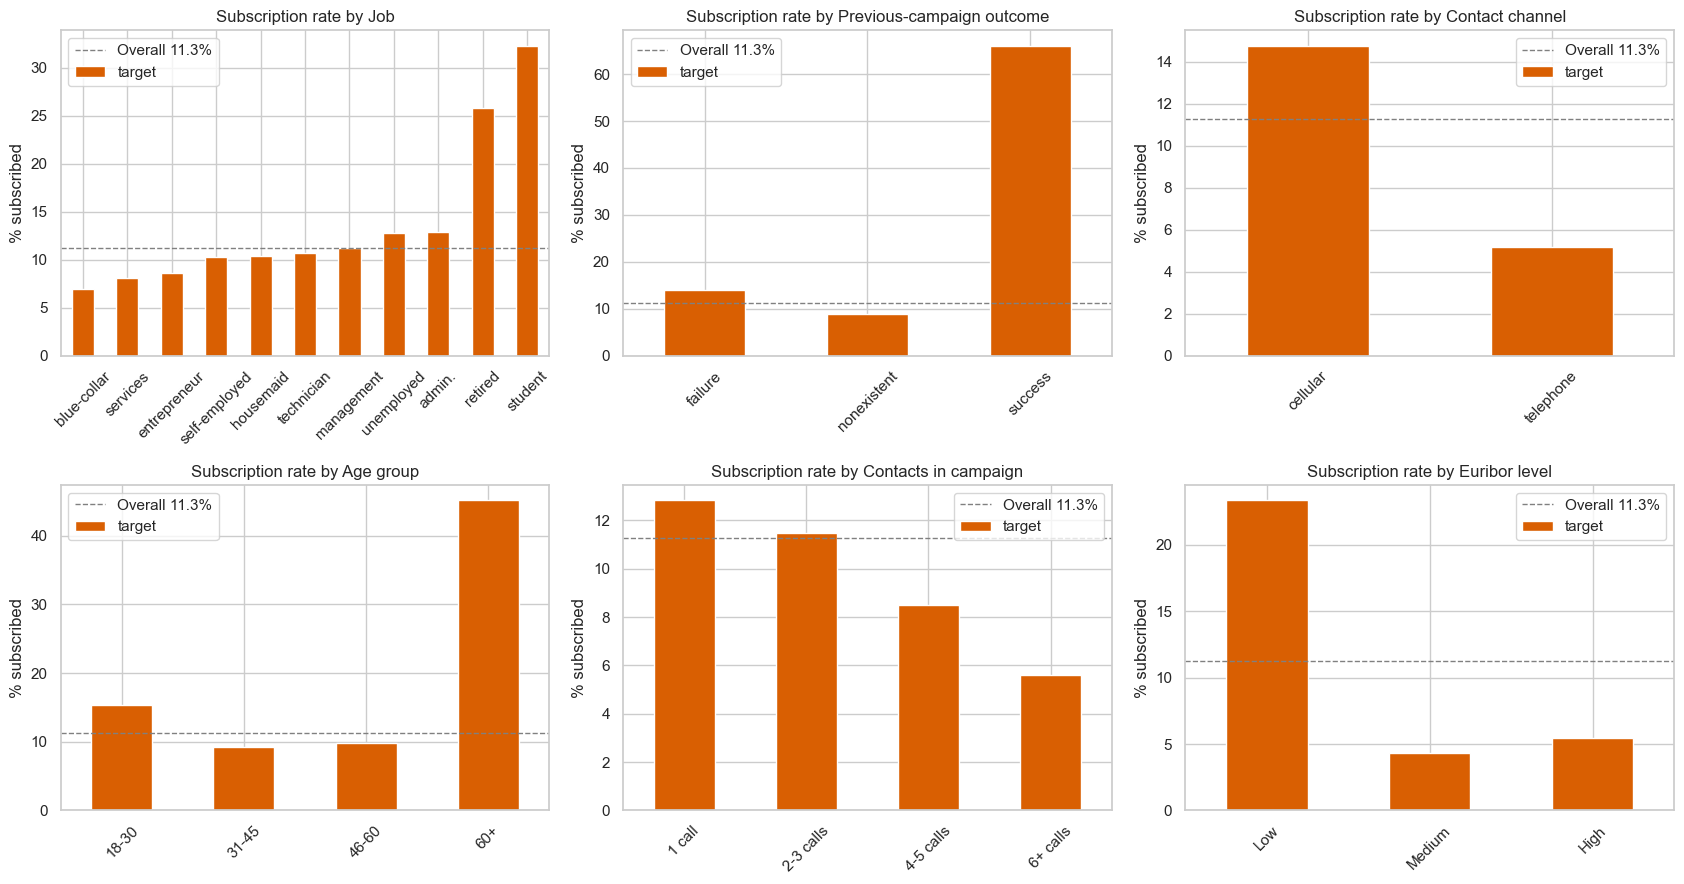

In [48]:
# 3.2 Bar charts – subscription rate by segment
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, title) in zip(axes.ravel(), [
        ('job', 'by Job'), ('poutcome', 'by Previous-campaign outcome'), ('contact', 'by Contact channel'),
        ('age_group', 'by Age group'), ('campaign_group', 'by Contacts in campaign'), ('euribor_level', 'by Euribor level')]):
    r = rate_by(col)
    if col == 'job':
        r = r.sort_values()
    r.plot(kind='bar', ax=ax, color=ORANGE, rot=45)
    ax.axhline(overall_rate, color='gray', ls='--', lw=1, label=f'Overall {overall_rate:.1f}%')
    ax.set_title(f'Subscription rate {title}')
    ax.set_ylabel('% subscribed'); ax.set_xlabel('')
    ax.legend()
plt.tight_layout()
plt.show()

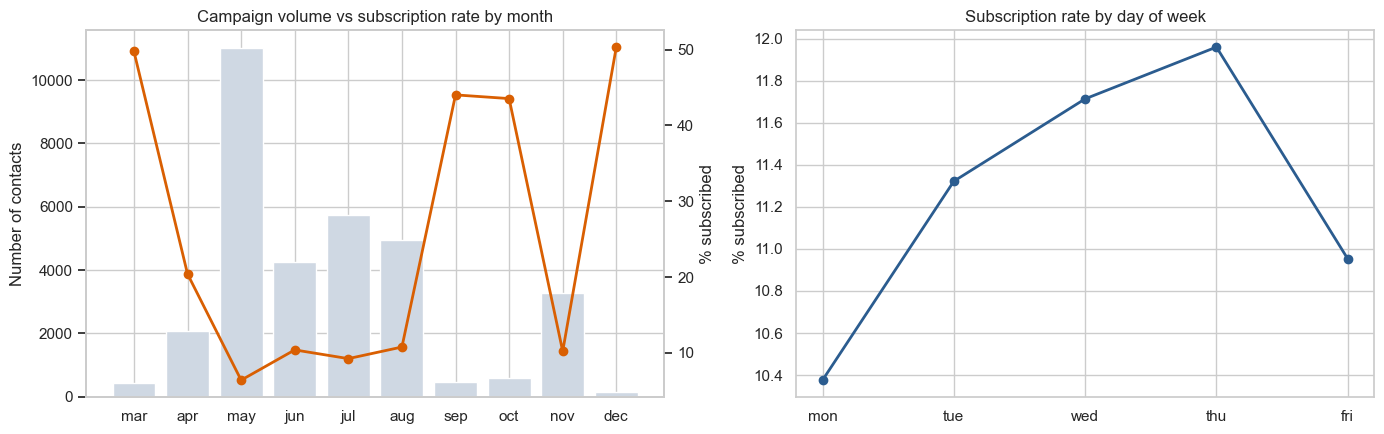

In [49]:
# 3.3 Line charts – trends over time
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

m_rate = rate_by('month')
m_cnt = eda['month'].value_counts().reindex(month_order)
ax[0].bar(m_cnt.index, m_cnt.values, color='#cfd8e3', label='Contacts (left)')
ax[0].set_ylabel('Number of contacts')
ax2 = ax[0].twinx()
ax2.plot(m_rate.index, m_rate.values, marker='o', color=ORANGE, lw=2, label='Subscription rate (right)')
ax2.set_ylabel('% subscribed'); ax2.grid(False)
ax[0].set_title('Campaign volume vs subscription rate by month')

d_rate = rate_by('day_of_week')
ax[1].plot(d_rate.index.astype(str), d_rate.values, marker='o', color=BLUE, lw=2)
ax[1].set_title('Subscription rate by day of week'); ax[1].set_ylabel('% subscribed')
plt.tight_layout()
plt.show()

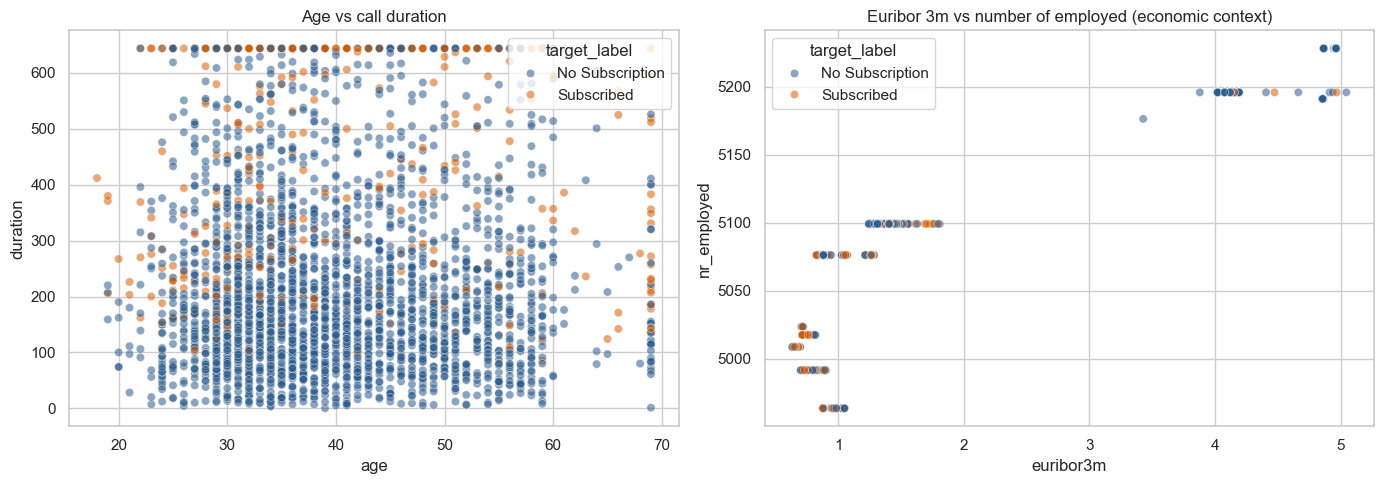

In [50]:
# 3.4 Scatter plots – relationships between variables
s = eda.sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=s, x='age', y='duration', hue='target_label', alpha=0.55, ax=ax[0],
                palette={'No Subscription': BLUE, 'Subscribed': ORANGE})
ax[0].set_title('Age vs call duration')
sns.scatterplot(data=s, x='euribor3m', y='nr_employed', hue='target_label', alpha=0.55, ax=ax[1],
                palette={'No Subscription': BLUE, 'Subscribed': ORANGE})
ax[1].set_title('Euribor 3m vs number of employed (economic context)')
plt.tight_layout()
plt.show()

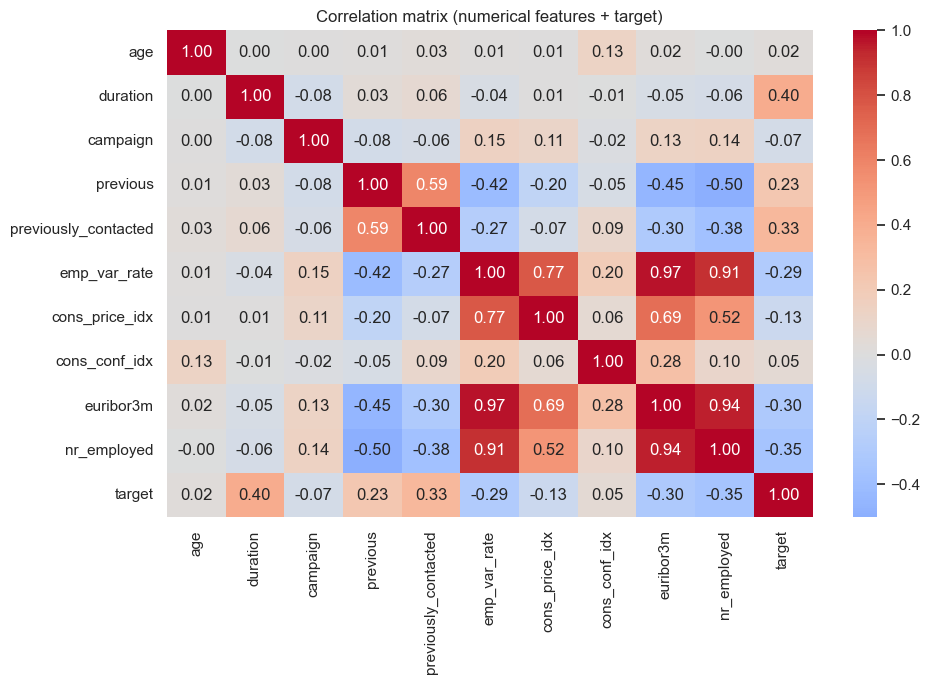

Correlation with target (sorted):
duration                0.401
nr_employed            -0.350
previously_contacted    0.329
euribor3m              -0.303
emp_var_rate           -0.294
previous                0.229
cons_price_idx         -0.132
campaign               -0.068
cons_conf_idx           0.054
age                     0.025


In [51]:
# 3.5 Correlation heat-map
num_df = eda[['age', 'duration', 'campaign', 'previous', 'previously_contacted', 'emp_var_rate',
             'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'target']]
plt.figure(figsize=(10, 7))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (numerical features + target)')
plt.tight_layout()
plt.show()

print('Correlation with target (sorted):')
print(num_df.corr()['target'].drop('target').sort_values(key=abs, ascending=False).round(3).to_string())

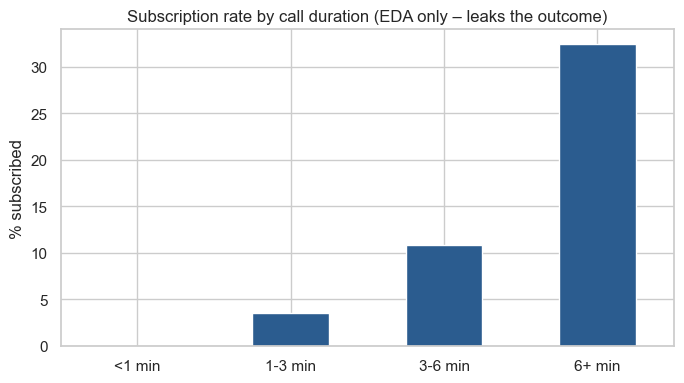

duration_group
<1 min      0.0
1-3 min     3.5
3-6 min    10.9
6+ min     32.4


In [52]:
# 3.6 Call duration vs outcome (analysis only – NOT used for prediction, see §4)
dur = rate_by('duration_group')
ax = dur.plot(kind='bar', color=BLUE, rot=0, figsize=(7, 4))
ax.set_title('Subscription rate by call duration (EDA only – leaks the outcome)')
ax.set_ylabel('% subscribed'); ax.set_xlabel('')
plt.tight_layout()
plt.show()
print(dur.round(1).to_string())

## 4) Predictive Modelling

**Models:** Logistic Regression, Decision Tree, Random Forest, Linear Regression, SVM (Linear SVM).
**Evaluation:** Accuracy and **confusion matrix** (required), plus Precision / Recall / F1 / ROC-AUC for the "Subscribed" class, because only ~11% of clients subscribe and accuracy alone can be misleading (a model that always says "No" already scores ~89%).

**Important design decisions**
1. **Leakage-safe pipeline:** the train/test split was made before cleaning (§2.4); imputation, capping, anomaly model, scaler and encoder all learn from training rows only.
2. **`duration` and `duration_group` are explicitly removed** from the predictors (call length is only known *after* the call). An `assert` below makes the notebook fail if either ever slips back in; §4.4 proves the leakage effect.
3. `pdays` (raw, with its 999 sentinel) is not used; the model gets `previously_contacted` plus the categorical `pdays_bucket`.
4. `is_anomaly` (Isolation-Forest flag, built from predictors only) is kept as a **signal** feature.
5. **Encoding & scaling** with scikit-learn `ColumnTransformer`: `OneHotEncoder` for categorical columns and `StandardScaler` for numeric columns only.
6. Two benchmark runs: **standard** (maximises accuracy) and **class-balanced** (finds more real subscribers, which is what the business needs).
7. **Linear Regression** (required by the brief) is used as a *linear probability model*: it predicts a continuous score for the 0/1 target, which is turned into a class with a threshold. Logistic Regression is the proper linear classifier and is the one to trust; Linear Regression is shown for comparison.

In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = ['age', 'campaign', 'previous', 'previously_contacted', 'is_anomaly',
                    'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed']
categorical_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                        'contact', 'month', 'day_of_week', 'poutcome', 'pdays_bucket']
model_features = numeric_features + categorical_features

# Post-call information must never reach the models
POST_CALL_COLS = ['duration', 'duration_group']
assert not set(POST_CALL_COLS) & set(model_features), 'Data leakage: post-call column found in the features!'
print('Leakage check passed – no post-call columns in the model features.')

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)])

def model_frame(cols):
    out = df[cols].copy()
    for c in categorical_features:
        if c in out.columns:
            out[c] = out[c].astype(str)         # plain strings for OneHotEncoder
    return out

X_all = model_frame(model_features)
y = df['target']
X_train, X_test = X_all[train_mask], X_all[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

preprocess = make_preprocessor(numeric_features, categorical_features)
X_train_s = preprocess.fit_transform(X_train)        # fitted on TRAIN only
X_test_s = preprocess.transform(X_test)
feature_names = [n.split('__', 1)[1] for n in preprocess.get_feature_names_out()]

print(f'Encoded features: {len(feature_names)} | Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')
print(f'Positive rate – train: {y_train.mean():.3f} | test: {y_test.mean():.3f}')

Leakage check passed – no post-call columns in the model features.
Encoded features: 51 | Train: 32,940 | Test: 8,236
Positive rate – train: 0.113 | test: 0.113


### 4.1 Benchmark – five models, two settings

In [54]:
def build_models(class_weight):
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=RANDOM_STATE),
        'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight=class_weight, random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, class_weight=class_weight,
                                                random_state=RANDOM_STATE, n_jobs=-1),
        'SVM (Linear)': LinearSVC(C=0.5, class_weight=class_weight, dual=False, max_iter=5000,
                                  random_state=RANDOM_STATE),
    }

def best_threshold(y_true, scores):
    grid = np.linspace(0.05, 0.60, 56)
    f1s = [f1_score(y_true, (scores >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))])

def metric_row(name, y_true, pred, score):
    return {'Model': name,
            'Accuracy (%)': round(accuracy_score(y_true, pred) * 100, 2),
            'Precision': round(precision_score(y_true, pred, zero_division=0), 3),
            'Recall': round(recall_score(y_true, pred), 3),
            'F1': round(f1_score(y_true, pred), 3),
            'ROC-AUC': round(roc_auc_score(y_true, score), 3)}

def run_benchmark(class_weight):
    rows, preds, fitted = [], {}, {}
    for name, model in build_models(class_weight).items():
        model.fit(X_train_s, y_train)
        pred = model.predict(X_test_s)
        score = (model.predict_proba(X_test_s)[:, 1] if hasattr(model, 'predict_proba')
                 else model.decision_function(X_test_s))
        rows.append(metric_row(name, y_test, pred, score))
        preds[name], fitted[name] = (pred, score), model

    # Linear Regression as a linear probability model
    lin = LinearRegression().fit(X_train_s, y_train)
    thr = 0.5 if class_weight is None else best_threshold(y_train, lin.predict(X_train_s))
    score = lin.predict(X_test_s)
    pred = (score >= thr).astype(int)
    name = f'Linear Regression (thr={thr:.2f})'
    rows.append(metric_row(name, y_test, pred, score))
    preds[name], fitted[name] = (pred, score), lin
    return pd.DataFrame(rows).set_index('Model'), preds, fitted

res_std, preds_std, fit_std = run_benchmark(class_weight=None)
res_bal, preds_bal, fit_bal = run_benchmark(class_weight='balanced')

baseline_acc = (1 - y_test.mean()) * 100
print(f'Baseline (always predict "No"): accuracy = {baseline_acc:.2f}%, recall = 0\n')
print('--- A) STANDARD models (optimise accuracy) ---')
display(res_std)
print('\n--- B) CLASS-BALANCED models (optimise finding subscribers) ---')
display(res_bal)

Baseline (always predict "No"): accuracy = 88.73%, recall = 0

--- A) STANDARD models (optimise accuracy) ---


,Accuracy (%),Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,89.86,0.654,0.212,0.321,0.800
Decision Tree,90.00,0.653,0.239,0.350,0.799
Random Forest,89.83,0.672,0.190,0.296,0.807
SVM (Linear),89.93,0.679,0.203,0.312,0.796
Linear Regression (thr=0.50),89.92,0.680,0.199,0.308,0.797



--- B) CLASS-BALANCED models (optimise finding subscribers) ---


,Accuracy (%),Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,83.03,0.359,0.645,0.461,0.800
Decision Tree,84.69,0.389,0.631,0.482,0.797
Random Forest,84.92,0.395,0.640,0.489,0.809
SVM (Linear),83.09,0.361,0.648,0.463,0.800
Linear Regression (thr=0.20),87.04,0.444,0.597,0.509,0.797


In [55]:
# Linear Regression as a regression model: how well does it predict the 0/1 target as a continuous score?
lin_std = fit_std[[k for k in fit_std if k.startswith('Linear')][0]]
s_pred = lin_std.predict(X_test_s)
print(f'Linear Regression on target -> R² = {r2_score(y_test, s_pred):.3f} | '
      f'RMSE = {np.sqrt(mean_squared_error(y_test, s_pred)):.3f}')
print('A low R² is expected for a binary target; that is why Logistic Regression is the proper linear model for classification.')

Linear Regression on target -> R² = 0.218 | RMSE = 0.280
A low R² is expected for a binary target; that is why Logistic Regression is the proper linear model for classification.


### 4.2 Confusion matrices

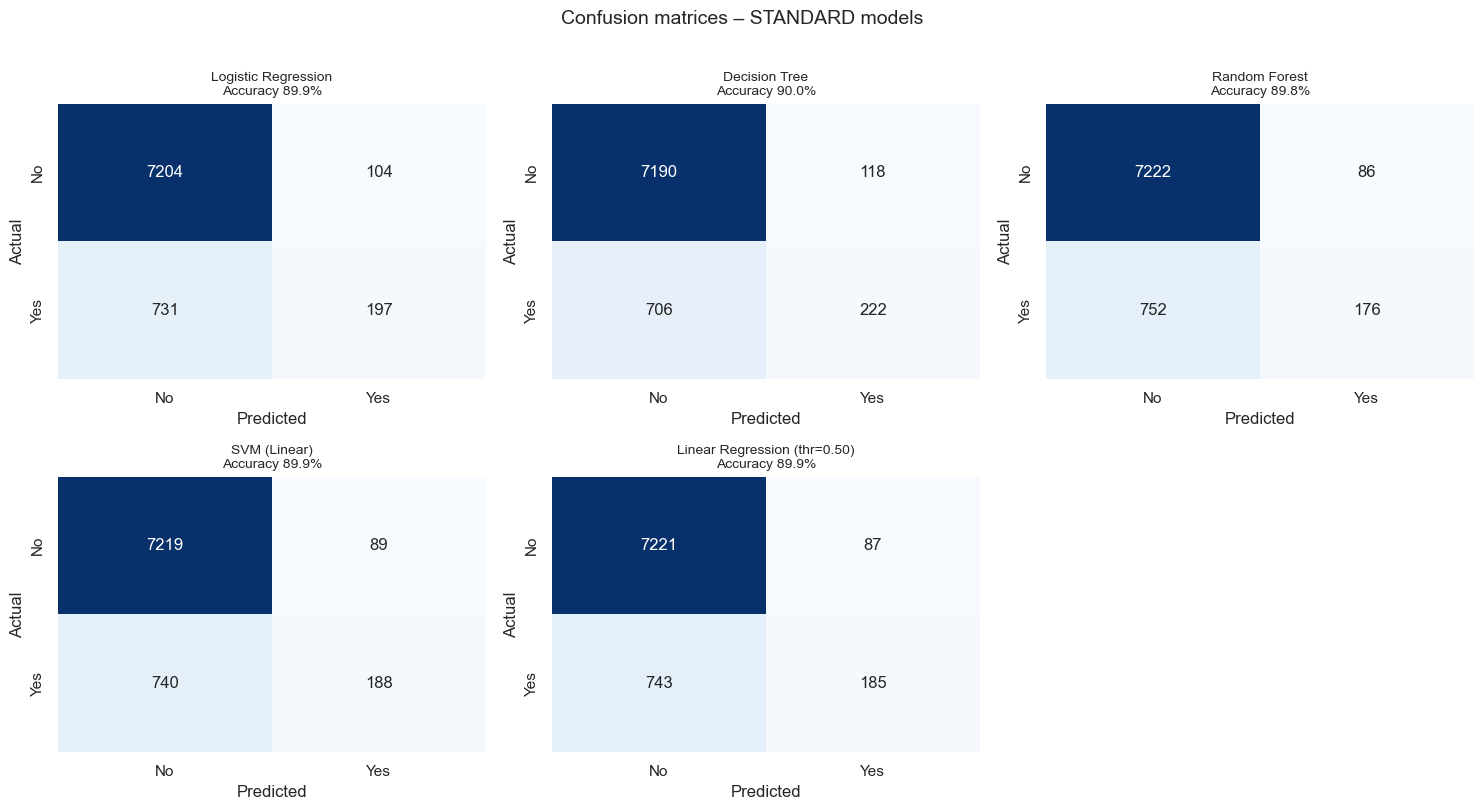

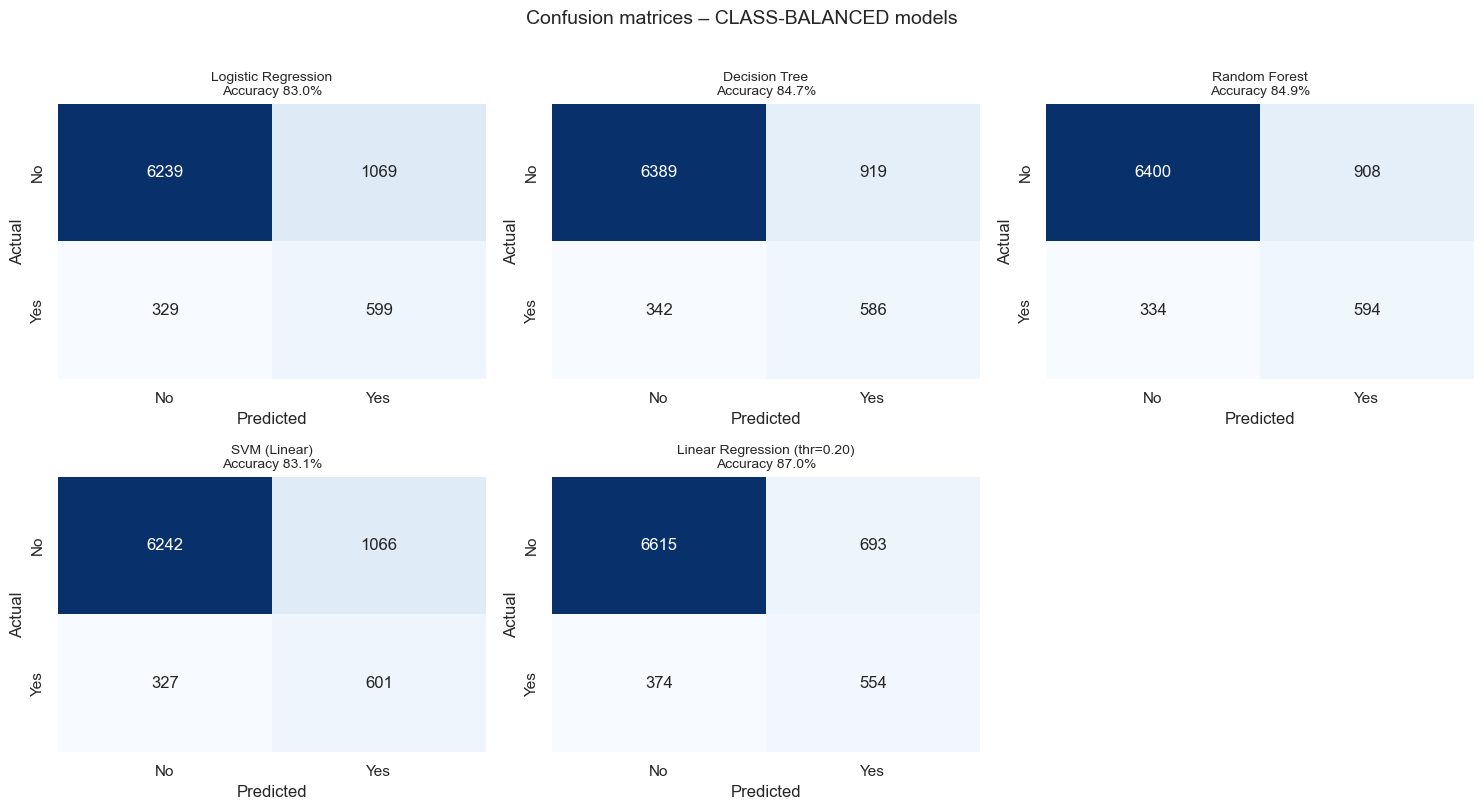

In [56]:
def plot_confusion_grid(preds, title):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.ravel()
    for ax, (name, (pred, _)) in zip(axes, preds.items()):
        cm = confusion_matrix(y_test, pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
        ax.set_title(f'{name}\nAccuracy {accuracy_score(y_test, pred):.1%}', fontsize=10)
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    for ax in axes[len(preds):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

plot_confusion_grid(preds_std, 'Confusion matrices – STANDARD models')
plot_confusion_grid(preds_bal, 'Confusion matrices – CLASS-BALANCED models')

### 4.3 Selecting the final model
The model used by the dashboard must output probabilities, so we pick the best **F1** among Logistic Regression, Decision Tree and Random Forest (class-balanced setting).

In [57]:
candidates = ['Logistic Regression', 'Decision Tree', 'Random Forest']
best_name = res_bal.loc[candidates, 'F1'].idxmax()
best_model = fit_bal[best_name]
best_pred, best_score = preds_bal[best_name]
print(f'Selected model: {best_name}\n')
print(classification_report(y_test, best_pred, target_names=['No Subscription', 'Subscribed'], digits=3))

Selected model: Random Forest

                 precision    recall  f1-score   support

No Subscription      0.950     0.876     0.912      7308
     Subscribed      0.395     0.640     0.489       928

       accuracy                          0.849      8236
      macro avg      0.673     0.758     0.700      8236
   weighted avg      0.888     0.849     0.864      8236



### 4.4 Why `duration` is excluded – a leakage check

In [58]:
pre_leak = make_preprocessor(numeric_features + ['duration'], categorical_features)
X_leak = model_frame(model_features + ['duration'])
Xl_tr = pre_leak.fit_transform(X_leak[train_mask]); Xl_te = pre_leak.transform(X_leak[~train_mask])
rf_leak = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced',
                                 random_state=RANDOM_STATE, n_jobs=-1).fit(Xl_tr, y_train)
auc_leak = roc_auc_score(y_test, rf_leak.predict_proba(Xl_te)[:, 1])
auc_clean = res_bal.loc['Random Forest', 'ROC-AUC']
print(f'Random Forest ROC-AUC WITHOUT duration: {auc_clean:.3f}  (honest, usable before the call)')
print(f'Random Forest ROC-AUC WITH duration   : {auc_leak:.3f}  (inflated – duration is only known after the call)')

Random Forest ROC-AUC WITHOUT duration: 0.809  (honest, usable before the call)
Random Forest ROC-AUC WITH duration   : 0.943  (inflated – duration is only known after the call)


### 4.4b Does the anomaly signal help?
The Isolation-Forest flag converts at ~50% (§2.8). We check whether keeping it as a feature changes Random Forest performance on the test set.

In [59]:
no_anom = [c for c in numeric_features if c != 'is_anomaly']
pre_na = make_preprocessor(no_anom, categorical_features)
Xn = model_frame(no_anom + categorical_features)
Xn_tr = pre_na.fit_transform(Xn[train_mask]); Xn_te = pre_na.transform(Xn[~train_mask])
rf_na = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced',
                               random_state=RANDOM_STATE, n_jobs=-1).fit(Xn_tr, y_train)
auc_na = roc_auc_score(y_test, rf_na.predict_proba(Xn_te)[:, 1])
print(f'Random Forest ROC-AUC without is_anomaly: {auc_na:.3f}')
print(f'Random Forest ROC-AUC with    is_anomaly: {res_bal.loc["Random Forest", "ROC-AUC"]:.3f}')

Random Forest ROC-AUC without is_anomaly: 0.808
Random Forest ROC-AUC with    is_anomaly: 0.809


### 4.5 What drives subscription? (feature importance)

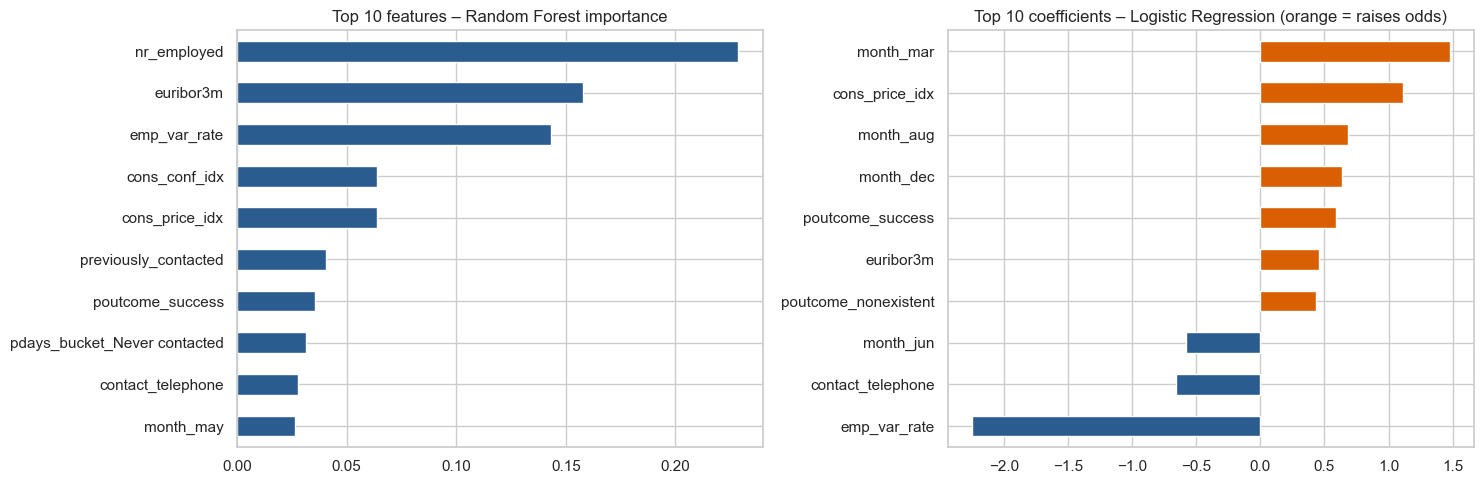

Top 5 drivers (Random Forest):
1. nr_employed               0.229
2. euribor3m                 0.158
3. emp_var_rate              0.143
4. cons_conf_idx             0.064
5. cons_price_idx            0.064


In [60]:
rf_model = fit_bal['Random Forest']
imp = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)
coef = pd.Series(fit_bal['Logistic Regression'].coef_[0], index=feature_names)
coef_top = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
imp.head(10).sort_values().plot(kind='barh', ax=ax[0], color=BLUE)
ax[0].set_title('Top 10 features – Random Forest importance')
coef_top.plot(kind='barh', ax=ax[1], color=[ORANGE if v > 0 else BLUE for v in coef_top])
ax[1].set_title('Top 10 coefficients – Logistic Regression (orange = raises odds)')
plt.tight_layout()
plt.show()

top_features = imp.head(5)
print('Top 5 drivers (Random Forest):')
for i, (k, v) in enumerate(top_features.items(), 1):
    print(f'{i}. {k:25s} {v:.3f}')

### 4.6 Predictive insight – how well does the model rank leads?
Clients in the test set are sorted by predicted probability and split into 10 equal groups (deciles). If the model is useful, the top deciles should convert far more than the average.

,clients,subscribers,conversion_rate_%,cum_subscribers_captured_%
decile,,,,
1,824,426,51.7,45.9
2,824,179,21.7,65.2
3,823,75,9.1,73.3
4,824,50,6.1,78.7
5,823,47,5.7,83.7
6,824,39,4.7,87.9
7,823,28,3.4,90.9
8,824,29,3.5,94.1
9,823,29,3.5,97.2


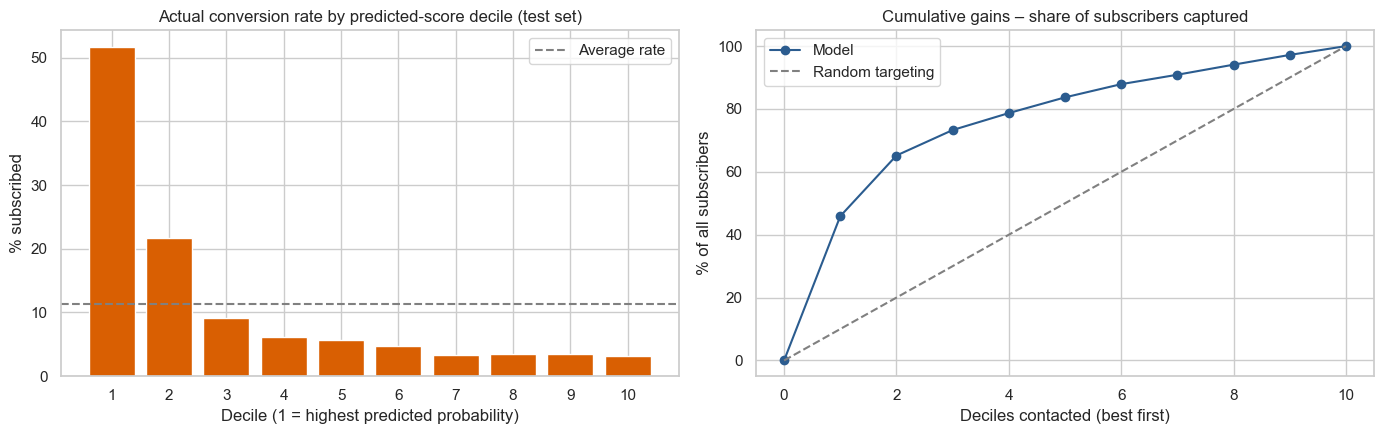

In [61]:
sc = pd.DataFrame({'score': best_score, 'y': y_test.values})
sc['decile'] = pd.qcut(sc['score'].rank(method='first', ascending=False), 10, labels=range(1, 11))
lift = sc.groupby('decile', observed=True).agg(clients=('y', 'size'), subscribers=('y', 'sum'))
lift['conversion_rate_%'] = (lift['subscribers'] / lift['clients'] * 100).round(1)
lift['cum_subscribers_captured_%'] = (lift['subscribers'].cumsum() / lift['subscribers'].sum() * 100).round(1)
display(lift)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(lift.index.astype(str), lift['conversion_rate_%'], color=ORANGE)
ax[0].axhline(y_test.mean() * 100, color='gray', ls='--', label='Average rate')
ax[0].set_title('Actual conversion rate by predicted-score decile (test set)')
ax[0].set_xlabel('Decile (1 = highest predicted probability)'); ax[0].set_ylabel('% subscribed'); ax[0].legend()
ax[1].plot(range(0, 11), [0] + lift['cum_subscribers_captured_%'].tolist(), marker='o', color=BLUE, label='Model')
ax[1].plot([0, 10], [0, 100], ls='--', color='gray', label='Random targeting')
ax[1].set_title('Cumulative gains – share of subscribers captured')
ax[1].set_xlabel('Deciles contacted (best first)'); ax[1].set_ylabel('% of all subscribers'); ax[1].legend()
plt.tight_layout()
plt.show()

## 5) AI-Generated Insights & Summary
The function below **automatically writes the insights in natural language** straight from the data and the model results (no numbers are typed by hand), so the summary updates whenever the data or models change.

In [62]:
def seg(col):
    return (eda.groupby(col, observed=True)['target'].mean() * 100).round(1)

def generate_insights():
    n, n_sub = len(eda), int(eda['target'].sum())
    jr = seg('job').sort_values(ascending=False)
    pr = seg('poutcome')
    cr = seg('contact')
    mr = seg('month')
    mc = eda['month'].value_counts()
    er = seg('euribor_level')
    ar = seg('age_group')
    cg = seg('campaign_group')
    dg = seg('duration_group')
    top_months = mr[mc[mr.index] >= 100].sort_values(ascending=False).head(3)
    busiest = mc.idxmax()

    b = res_bal.loc[best_name]
    top_dec = lift['cum_subscribers_captured_%'].iloc[0]
    top3_dec = lift['cum_subscribers_captured_%'].iloc[2]

    findings = [
        f"Overall, {overall_rate:.1f}% of {n:,} training contacts subscribed ({n_sub:,} clients). The data is imbalanced, so accuracy alone is misleading – recall and F1 matter more.",
        f"Job matters: {jr.index[0]} ({jr.iloc[0]}%) and {jr.index[1]} ({jr.iloc[1]}%) convert best, while {jr.index[-1]} converts worst ({jr.iloc[-1]}%).",
        f"Past success predicts future success: clients who subscribed in a previous campaign convert at {pr['success']}%, versus {pr['nonexistent']}% for clients never contacted before – about {pr['success'] / pr['nonexistent']:.1f}x higher.",
        f"Channel: cellular contacts convert at {cr['cellular']}% versus {cr['telephone']}% for landline telephone.",
        f"Seasonality: {busiest.upper()} is the busiest month ({mc[busiest]:,} calls) but converts only {mr[busiest]}%; the strongest months with meaningful volume are "
        + ', '.join(f"{m.upper()} ({v}%)" for m, v in top_months.items()) + '.',
        f"Economy: when the 3-month Euribor is low, {er['Low']}% subscribe versus {er['High']}% when it is high – term deposits are more attractive in low-rate periods.",
        f"Age: clients aged 60+ convert at {ar['60+']}% compared with {ar['31-45']}% for ages 31-45.",
        f"Contact pressure: clients called once convert at {cg['1 call']}%, falling to {cg['6+ calls']}% after 6 or more calls – repeated calls show diminishing returns.",
        f"Anomalies are an opportunity, not noise: the {int(eda['is_anomaly'].sum())} unusual records (multivariate outliers, concentrated in {', '.join(m.upper() for m in anom_months.index[:3])}) convert at {seg('is_anomaly')[1]}% versus {seg('is_anomaly')[0]}% for normal records, so they were kept and used as a predictive signal.",
        f"Call length (analysis only): calls over 6 minutes convert at {dg['6+ min']}% versus {dg['<1 min']}% for calls under 1 minute – engagement matters, but call length cannot be used to pre-select clients.",
    ]
    model_text = [
        f"The selected model is {best_name} (class-balanced): accuracy {b['Accuracy (%)']}%, recall {b['Recall']:.0%}, precision {b['Precision']:.0%}, F1 {b['F1']}, ROC-AUC {b['ROC-AUC']}.",
        f"The always-'No' baseline reaches {baseline_acc:.1f}% accuracy but finds zero subscribers, so the balanced model gives up some accuracy to find far more real subscribers.",
        f"Ranking quality: contacting only the top 10% of clients (by predicted probability) captures {top_dec:.0f}% of all subscribers, and the top 30% captures {top3_dec:.0f}% – versus 10% and 30% with random calling.",
        'Top drivers of the prediction: ' + ', '.join(top_features.index[:5]) + '.',
        f"Linear Regression explains little of the 0/1 target (R² = {r2_score(y_test, s_pred):.2f}) and ranks clients slightly worse than Logistic Regression (ROC-AUC {res_bal.iloc[-1]['ROC-AUC']} vs {res_bal.loc['Logistic Regression', 'ROC-AUC']}); it is kept for comparison, while Logistic Regression is the appropriate linear classifier.",
    ]
    recs = [
        f"Prioritise the call list by model score: start with the top two deciles, which convert at {lift['conversion_rate_%'].iloc[0]}% and {lift['conversion_rate_%'].iloc[1]}% versus the {overall_rate:.1f}% average.",
        "Re-contact clients from previous successful campaigns first – they are the cheapest, highest-converting segment.",
        "Shift calls to cellular numbers and cap repeated attempts at about 3-4 calls per client to protect agent time.",
        "Plan campaign timing around interest-rate conditions: increase effort when Euribor is low, and avoid heavy volume in low-yield months.",
        "Build tailored offers for students, retirees and older clients, who respond best, instead of one generic script.",
        "Treat the unusual-economic-condition segment (flagged anomalies) as a priority campaign window rather than discarding it as noise.",
        "Train agents on engagement (longer, higher-quality conversations lift conversion), but do not use call length to select leads.",
    ]
    return findings, model_text, recs

findings, model_text, recs = generate_insights()

summary_md = '# AI-Generated Insights Summary\n\n## Key data findings\n' + '\n'.join(f'- {t}' for t in findings)
summary_md += '\n\n## Model results explained\n' + '\n'.join(f'- {t}' for t in model_text)
summary_md += '\n\n## Business recommendations\n' + '\n'.join(f'{i}. {t}' for i, t in enumerate(recs, 1))

with open(f'{OUTPUT_DIR}/ai_insights_summary.md', 'w', encoding='utf-8') as f:
    f.write(summary_md)
print(summary_md)

# AI-Generated Insights Summary

## Key data findings
- Overall, 11.3% of 32,940 training contacts subscribed (3,711 clients). The data is imbalanced, so accuracy alone is misleading – recall and F1 matter more.
- Job matters: student (32.3%) and retired (25.8%) convert best, while blue-collar converts worst (6.9%).
- Past success predicts future success: clients who subscribed in a previous campaign convert at 66.0%, versus 8.8% for clients never contacted before – about 7.5x higher.
- Channel: cellular contacts convert at 14.7% versus 5.2% for landline telephone.
- Seasonality: MAY is the busiest month (11,019 calls) but converts only 6.4%; the strongest months with meaningful volume are DEC (50.3%), MAR (49.8%), SEP (44.0%).
- Economy: when the 3-month Euribor is low, 23.3% subscribe versus 5.4% when it is high – term deposits are more attractive in low-rate periods.
- Age: clients aged 60+ convert at 45.1% compared with 9.2% for ages 31-45.
- Contact pressure: clients called once c